## Multi-armed bandit problem and the Dirichlet distribution

The choice of a subjective prior does not always imply that we are using the practitioner's subjective opinion: more often the subjective prior was once a posterior to a previous problem, and now the practitioner is updating this posterior with new data. A subjective prior can also be used to inject *domain knowledge* of the problem into the model. We will see examples of these two situations later.

### Refresh: The Beta distribution

You may have seen the term `beta` in previous code in this book. Often, I was implementing a Beta distribution. The Beta distribution is very useful in Bayesian statistics. A random variable $X$ has a $\text{Beta}$ distribution, with parameters $(\alpha, \beta)$, if its density function is:

$$f_X(x | \; \alpha, \beta ) = \frac{ x^{(\alpha - 1)}(1-x)^{ (\beta - 1) } }{B(\alpha, \beta) }$$

where $B$ is the [Beta function](http://en.wikipedia.org/wiki/Beta_function) (hence the name). The random variable $X$ is only allowed in [0,1], making the Beta distribution a popular distribution for decimal values, probabilities and proportions. The values of $\alpha$ and $\beta$, both positive values, provide great flexibility in the shape of the distribution. Below we plot some distributions:

In [43]:
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt
import scipy

# Beta distribution
## $p\sim(\alpha, \beta)$
## $p \in [0,1]$

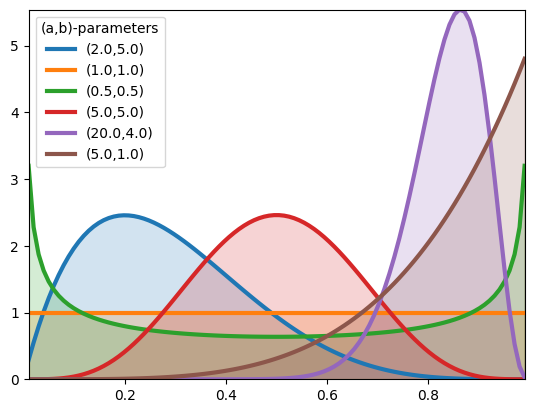

In [40]:
# figsize(12.5, 5)

params = [(2, 5), (1, 1), (0.5, 0.5), (5, 5), (20, 4), (5, 1)]

x = np.linspace(0.01, .99, 100)
beta = stats.beta
for a, b in params:
    y = beta.pdf(x, a, b)
    lines = plt.plot(x, y, label = "(%.1f,%.1f)"%(a,b), lw = 3)
    plt.fill_between(x, 0, y, alpha = 0.2, color = lines[0].get_color())
    plt.autoscale(tight=True)
plt.ylim(0)
plt.legend(loc = 'upper left', title="(a,b)-parameters");

## Posterior computaiton:
## If:
### Prior: $p\sim(\alpha, \beta)$,
### Likelihood: $X\sim \text{Binomial}(N, p)$.
## Then:
## Posterior: $p | X \sim \text{Beta}( \alpha + X, \beta + N -X )$

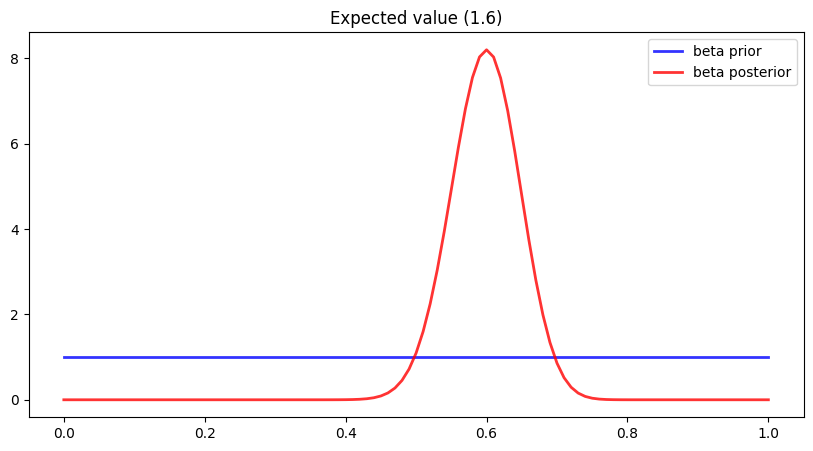

In [56]:
alpha = 1
beta = 1
n_trial = 100
n_sucsses = 60
plt.figure(figsize = (10,5))
plt.title("Expected value (%0.1f)"%(alpha+n_sucsses/(alpha+n_sucsses + beta+n_trial - n_sucsses)))
r=np.arange(0.,1.01,.01)
# plt.xlim(0.1,0.6)
# plt.ylim(0.,16.)
# plt.hist(samples_for_hist, density = True, bins =30)
plt.plot(r, scipy.stats.beta.pdf(r, alpha, beta), 'b-', lw=2, alpha=0.8, label='beta prior')
plt.plot(r, scipy.stats.beta.pdf(r, alpha+n_sucsses, beta+n_trial - n_sucsses), 'r-', lw=2, alpha=0.8, label='beta posterior')
plt.legend()
plt.show()

One thing I'd like the reader to notice is the presence of the flat distribution above, specified by parameters $(1,1)$. This is the Uniform distribution. Hence the Beta distribution is a generalization of the Uniform distribution, something we will revisit many times.

There is an interesting connection between the Beta distribution and the Binomial distribution. Suppose we are interested in some unknown proportion or probability $p$. We assign a $\text{Beta}(\alpha, \beta)$ prior to $p$. We observe some data generated by a Binomial process, say $X \sim \text{Binomial}(N, p)$, with $p$ still unknown. Then our posterior *is again a Beta distribution*, i.e. $p | X \sim \text{Beta}( \alpha + X, \beta + N -X )$. Succinctly, one can relate the two by "a Beta prior with Binomial observations creates a Beta posterior". This is a very useful property, both computationally and heuristically.

In light of the above two paragraphs, if we start with a $\text{Beta}(1,1)$ prior on $p$ (which is a Uniform), observe data $X \sim \text{Binomial}(N, p)$, then our posterior is $\text{Beta}(1 + X, 1 + N - X)$. 


##### Example: Bayesian Multi-Armed Bandits
*Adapted from an example by Ted Dunning of MapR Technologies*

> Suppose you are faced with $N$ slot machines (colourfully called multi-armed bandits). Each bandit has an unknown probability of distributing a prize (assume for now the prizes are the same for each bandit, only the probabilities differ). Some bandits are very generous, others not so much. Of course, you don't know what these probabilities are. By only choosing one bandit per round, our task is devise a strategy to maximize our winnings.

Of course, if we knew the bandit with the largest probability, then always picking this bandit would yield the maximum winnings. So our task can be phrased as "Find the best bandit, and as quickly as possible". 

The task is complicated by the stochastic nature of the bandits. A suboptimal bandit can return many winnings, purely by chance, which would make us believe that it is a very profitable bandit. Similarly, the best bandit can return many duds. Should we keep trying losers then, or give up? 

A more troublesome problem is, if we have found a bandit that returns *pretty good* results, do we keep drawing from it to maintain our *pretty good score*, or do we try other bandits in hopes of finding an *even-better* bandit? This is the exploration vs. exploitation dilemma.

### Applications


The Multi-Armed Bandit problem at first seems very artificial, something only a mathematician would love, but that is only before we address some applications:

- Internet display advertising: companies have a suite of potential ads they can display to visitors, but the company is not sure which ad strategy to follow to maximize sales. This is similar to A/B testing, but has the added advantage of naturally minimizing strategies that do not work (and generalizes to A/B/C/D... strategies)
- Ecology: animals have a finite amount of energy to expend, and following certain behaviours has uncertain rewards. How does the animal maximize its fitness?
- Finance: which stock option gives the highest return, under time-varying return profiles.
- Clinical trials: a researcher would like to find the best treatment, out of many possible treatment, while minimizing losses. 
- Psychology: how does punishment and reward affect our behaviour? How do humans learn?

Many of these questions above are fundamental to the application's field.

It turns out the *optimal solution* is incredibly difficult, and it took decades for an overall solution to develop. There are also many approximately-optimal solutions which are quite good. The one I wish to discuss is one of the few solutions that can scale incredibly well. The solution is known as *Bayesian Bandits*.


### A Proposed Solution


Any proposed strategy is called an *online algorithm* (not in the internet sense, but in the continuously-being-updated sense), and more specifically a reinforcement learning algorithm. The algorithm starts in an ignorant state, where it knows nothing, and begins to acquire data by testing the system. As it acquires data and results, it learns what the best and worst behaviours are (in this case, it learns which bandit is the best). With this in mind, perhaps we can add an additional application of the Multi-Armed Bandit problem:

- Psychology: how does punishment and reward affect our behaviour? How do humans learn?


The Bayesian solution begins by assuming priors on the probability of winning for each bandit. In our vignette we assumed complete ignorance of these probabilities. So a very natural prior is the flat prior over 0 to 1. The algorithm proceeds as follows:

For each round:

1. Sample a random variable $X_b$ from the posterior of bandit $b$, for all $b$.
2. Select the bandit with largest sample, i.e. select $B = \text{argmax}\;\; X_b$.
3. Observe the result of pulling bandit $B$, and update your posterior on bandit $B$.
4. Return to 1.

That's it. Computationally, the algorithm involves sampling from $N$ distributions. Since the initial priors are $\text{Beta}(\alpha=1,\beta=1)$ (a uniform distribution), and the observed result $X$ (a win or loss, encoded 1 and 0 respectfully) is Binomial, the posterior is a $\text{Beta}(\alpha=1+X,\beta=1+1−X)$.

To answer our question from before, this algorithm suggests that we should not discard losers, but we should pick them at a decreasing rate as we gather confidence that there exist *better* bandits. This follows because there is always a non-zero chance that a loser will achieve the status of $B$, but the probability of this event decreases as we play more rounds (see figure below).

Below we implement Bayesian Bandits using two classes, `Bandits` that defines the slot machines, and `BayesianStrategy` which implements the above learning strategy.

In [27]:
import numpy as np
rand = np.random.rand

class Bandits(object):
    """
    This class represents N bandits machines.

    parameters:
        p_array: a (n,) Numpy array of probabilities >0, <1.

    methods:
        pull( i ): return the results, 0 or 1, of pulling 
                   the ith bandit.
    """
    def __init__(self, p_array):
        self.p = p_array
        self.optimal = np.argmax(p_array)
        
    def pull(self, i):
        #i is which arm to pull
        return np.random.rand() < self.p[i]
    
    def __len__(self):
        return len(self.p)

    
class BayesianStrategy(object):
    """
    Implements a online, learning strategy to solve
    the Multi-Armed Bandit problem.
    
    parameters:
        bandits: a Bandit class with .pull method
    
    methods:
        sample_bandits(n): sample and train on n pulls.

    attributes:
        N: the cumulative number of samples
        choices: the historical choices as a (N,) array
        bb_score: the historical score as a (N,) array
    """
    
    def __init__(self, bandits):
        
        self.bandits = bandits
        n_bandits = len(self.bandits)
        self.wins = np.zeros(n_bandits)
        self.trials = np.zeros(n_bandits)
        self.N = 0
        self.choices = []
        self.bb_score = []

    
    def sample_bandits(self, n=1):
        
        bb_score = np.zeros(n)
        choices = np.zeros(n)
        
        for k in range(n):
            #sample from the bandits's priors, and select the largest sample
            choice = np.argmax(np.random.beta(1 + self.wins, 1 + self.trials - self.wins))
            
            #sample the chosen bandit
            result = self.bandits.pull(choice)
            
            #update priors and score
            self.wins[choice] += result
            self.trials[choice] += 1
            bb_score[k] = result 
            self.N += 1
            choices[k] = choice
            
   
        self.bb_score = np.r_[self.bb_score, bb_score]
        self.choices = np.r_[self.choices, choices]
        return 

Below we visualize the learning of the Bayesian Bandit solution.

In [28]:
import matplotlib.pyplot as plt
plt.figure(figsize=(11.0, 10))
 
beta = stats.beta
x = np.linspace(0.001,.999,200)

def plot_priors(bayesian_strategy, prob, lw = 3, alpha = 0.2, plt_vlines = True):
    ## plotting function
    wins = bayesian_strategy.wins
    trials = bayesian_strategy.trials
    for i in range(prob.shape[0]):
        y = beta(1+wins[i], 1 + trials[i] - wins[i])
        p = plt.plot(x, y.pdf(x), lw = lw)
        c = p[0].get_markeredgecolor()
        plt.fill_between(x,y.pdf(x),0, color = c, alpha = alpha, 
                         label="underlying probability: %.2f" % prob[i])
        if plt_vlines:
            plt.vlines(prob[i], 0, y.pdf(prob[i]) ,
                       colors = c, linestyles = "--", lw = 2)
        plt.autoscale(tight = "True")
        plt.title("Posteriors After %d pull" % bayesian_strategy.N +\
                    "s"*(bayesian_strategy.N > 1))
        plt.autoscale(tight=True)
        
    return

<Figure size 1100x1000 with 0 Axes>

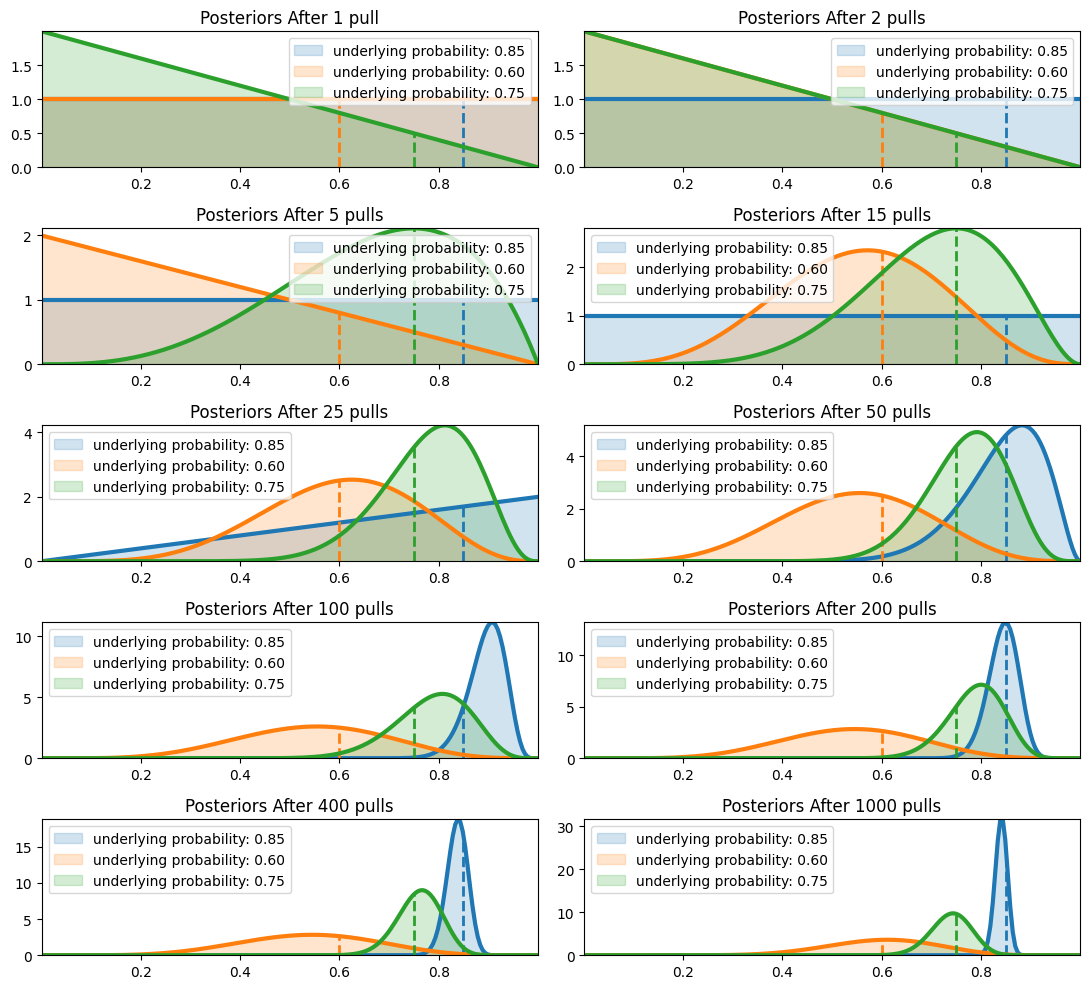

In [29]:
plt.figure(figsize=(11.0, 10))
hidden_prob = np.array([0.85, 0.60, 0.75])
bandits = Bandits(hidden_prob)
bayesian_strat = BayesianStrategy(bandits)

draw_samples = [1, 1, 3, 10, 10, 25, 50, 100, 200, 600]

for j,i in enumerate(draw_samples):
    plt.subplot(5, 2, j+1) 
    bayesian_strat.sample_bandits(i)
    plot_priors(bayesian_strat, hidden_prob)
    plt.legend()
    plt.autoscale(tight = True)
plt.tight_layout()

Note that we don't really care how accurate we become about the inference of the hidden probabilities &mdash; for this problem we are more interested in choosing the best bandit (or more accurately, becoming *more confident* in choosing the best bandit). For this reason, the distribution of the red bandit is very wide (representing ignorance about what that hidden probability might be) but we are reasonably confident that it is not the best, so the algorithm chooses to ignore it.

From the above, we can see that after 1000 pulls, the majority of the "blue" function leads the pack, hence we will almost always choose this arm. This is good, as this arm is indeed the best.

Below is a D3 app that demonstrates our algorithm updating/learning three bandits.  The first figure are the raw counts of pulls and wins, and the second figure is a dynamically updating plot. I encourage you to try to guess which bandit is optimal, prior to revealing the true probabilities, by selecting the `arm buttons`.

In [9]:
from IPython.core.display import HTML

#try executing the below command twice if the first time doesn't work
HTML(filename = "BanditsD3.html")

Deviations of the observed ratio from the highest probability is a measure of performance. For example,in the long run, optimally we can attain the reward/pull ratio of the maximum bandit probability. Long-term realized ratios less than the maximum represent inefficiencies. (Realized ratios larger than the maximum probability is due to randomness, and will eventually fall below). 

### A Measure of *Good*

We need a metric to calculate how well we are doing. Recall the absolute *best* we can do is to always pick the bandit with the largest probability of winning. Denote this best bandit's probability by $w_{opt}$. Our score should be relative to how well we would have done had we chosen the best bandit from the beginning. This motivates the *total regret* of a strategy, defined:

\begin{align}
R_T & = \sum_{i=1}^{T} \left( w_{opt} - w_{B(i)} \right)\\\\
& = Tw^* - \sum_{i=1}^{T} \;  w_{B(i)} 
\end{align}


where $w_{B(i)}$ is the probability of a prize of the chosen bandit in the $i$ round. A total regret of 0 means the strategy is matching the best possible score. This is likely not possible, as initially our algorithm will often make the wrong choice.  Ideally, a strategy's total regret should flatten as it learns the best bandit. (Mathematically, we achieve $w_{B(i)}=w_{opt}$ often)


Below we plot the total regret of this simulation, including the scores of some other strategies:

1. Random: randomly choose a bandit to pull. If you can't beat this, just stop. 
2. Largest Bayesian credible bound: pick the bandit with the largest upper bound in its 95% credible region of the underlying probability. 
3. Bayes-UCB algorithm: pick the bandit with the largest *score*, where score is a dynamic quantile of the posterior
3. Mean of posterior: choose the bandit with the largest posterior mean. 
3. Largest proportion: pick the bandit with the current largest observed proportion of winning. 

The code for these are in the `other_strats.py`, where you can implement your own very easily.

In [30]:
%matplotlib inline
import numpy as np
import scipy.stats as stats
from IPython.core.pylabtools import figsize
import matplotlib.pyplot as plt

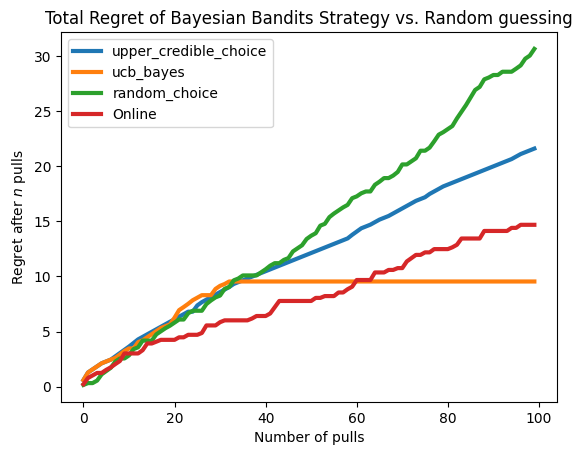

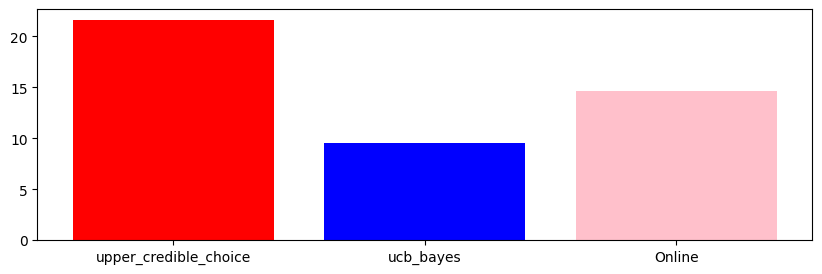

In [31]:
num_samples = 100

# figsize(12.5, 5)
from other_strats import *

num_arms = 10
#define a harder problem

hidden_prob = np.random.rand(num_arms)
bandits = Bandits(hidden_prob)

#define regret
def regret(probabilities, choices):
    w_opt = probabilities.max()
    return (w_opt - probabilities[choices.astype(int)]).cumsum()

#create new strategies
strategies= [upper_credible_choice, 
             
            ucb_bayes , 
            random_choice]
algos = []
for strat in strategies:
    algos.append(GeneralBanditStrat(bandits, strat))
    
#train 10000 times
for strat in algos:
    strat.sample_bandits(num_samples)
    
#test and plot
regret_dict = {}
for i,strat in enumerate(algos):
    _regret = regret(hidden_prob, strat.choices)
    if strategies[i].__name__ != 'random_choice':
        regret_dict[strategies[i].__name__] = _regret[-1]
    plt.plot(_regret, label = strategies[i].__name__, lw = 3)
    
bandits = Bandits(hidden_prob)
bayesian_strat = BayesianStrategy(bandits)


bayesian_strat.sample_bandits(num_samples)

regret_tompson = regret(hidden_prob, bayesian_strat.choices) 
regret_dict['Online'] = regret_tompson[-1]
plt.plot(regret_tompson, label = 'Online', lw = 3)

plt.title("Total Regret of Bayesian Bandits Strategy vs. Random guessing")
plt.xlabel("Number of pulls")
plt.ylabel("Regret after $n$ pulls");
plt.legend(loc = "upper left");

plt.figure(figsize=(10,3))
plt.bar(regret_dict.keys(), regret_dict.values(), color = ('red', 'blue', 'pink', 'orange'))
plt.show()

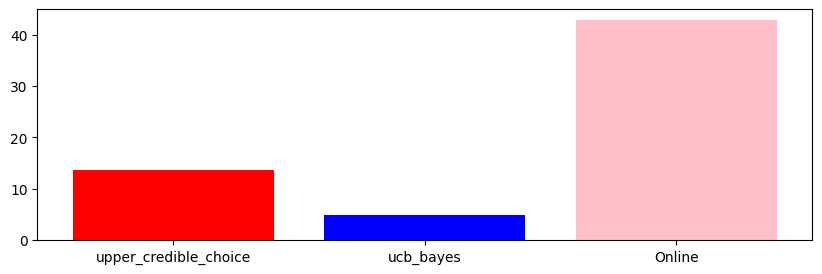

In [38]:
num_samples = 100


from other_strats import *

num_arms = 100
#define a harder problem

hidden_prob = np.random.rand(num_arms)
bandits = Bandits(hidden_prob)

#define regret
def regret(probabilities, choices):
    w_opt = probabilities.max()
    return (w_opt - probabilities[choices.astype(int)]).cumsum()

#create new strategies
strategies= [upper_credible_choice, 
            ucb_bayes , 
            random_choice]
algos = []
for strat in strategies:
    algos.append(GeneralBanditStrat(bandits, strat))
    
#train 10000 times
for strat in algos:
    strat.sample_bandits(num_samples)
    
#test and plot
regret_dict = {}
for i,strat in enumerate(algos):
    _regret = regret(hidden_prob, strat.choices)
    if strategies[i].__name__ != 'random_choice':
        regret_dict[strategies[i].__name__] = _regret[-1]
    
bandits = Bandits(hidden_prob)
bayesian_strat = BayesianStrategy(bandits)


bayesian_strat.sample_bandits(num_samples)

regret_tompson = regret(hidden_prob, bayesian_strat.choices) 
regret_dict['Online'] = regret_tompson[-1]


plt.figure(figsize=(10,3))
plt.bar(regret_dict.keys(), regret_dict.values(), color = ('red', 'blue', 'pink', 'orange'))
plt.show()

In [33]:
regret_dict

{'upper_credible_choice': np.float64(27.840778127005997),
 'bayesian_bandit_choice': np.float64(39.68111879588575),
 'ucb_bayes': np.float64(17.26233593580642),
 'Online': np.float64(41.81440427117172)}